In [4]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torch_geometric.datasets import Planetoid

In [5]:
import os
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

In [6]:
dataset = Planetoid(root="data/Planetoid", name="Cora")

data = dataset[0]

print(f"Numbers of Papers (Nodes): {data.num_nodes}")
print(f"Numbers of Citations (Edges): {data.num_edges}")
print(f"Features per paper : {data.num_node_features}")
print(f"Number of topics: {dataset.num_classes}")
print(f"Training Papers: {data.train_mask.sum()}")
print(f"Validation Papers: {data.val_mask.sum()}")
print(f"Testing Papers: {data.test_mask.sum()}")

Processing...
Done!


Numbers of Papers (Nodes): 2708
Numbers of Citations (Edges): 10556
Features per paper : 1433
Number of topics: 7
Training Papers: 140
Validation Papers: 500
Testing Papers: 1000


In [7]:
data

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])

<Axes: xlabel='None', ylabel='count'>

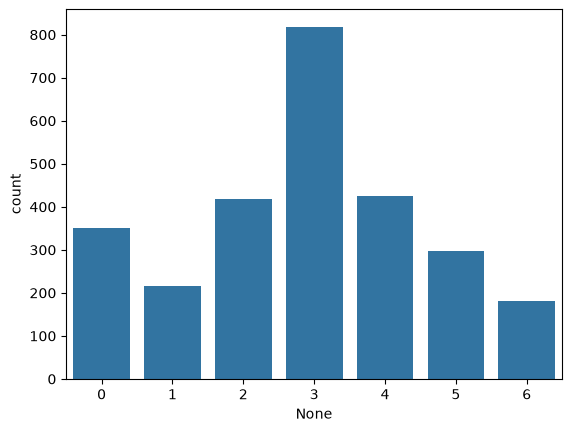

In [8]:
topic_counts = pd.Series(data.y.numpy()).value_counts().sort_index()

sns.barplot(x=topic_counts.index, y=topic_counts)

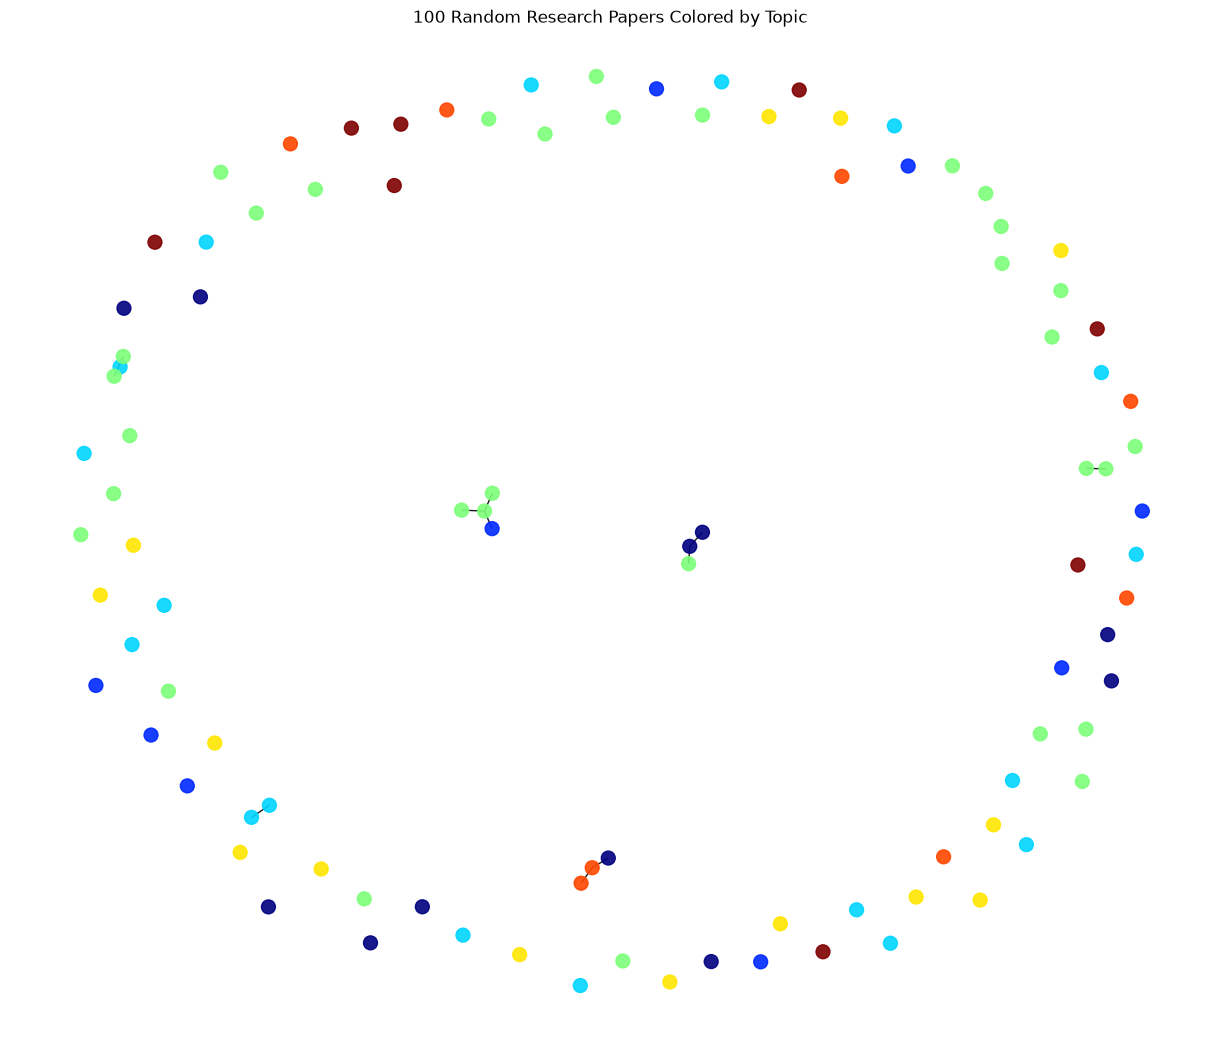

In [9]:
from torch_geometric.utils import to_networkx

import networkx as nx
import random
import matplotlib.pyplot as plt


SEED = 12345

# Convert the PyTorch Geometric data object to a NetworkX graph
G = to_networkx(data, to_undirected=True)

# Select 100 random nodes
random.seed(SEED)
sampled_nodes = random.sample(list(G.nodes()), 100)

# Create a graph using only those nodes
sample_graph = G.subgraph(sampled_nodes)

# Get the topic of each node
node_colors = [
    data.y[node].item()
    for node in sample_graph.nodes()
]

# Create positions for the nodes
pos = nx.spring_layout(sample_graph, seed=SEED)

# Draw the graph
plt.figure(figsize=(12, 10))

nx.draw(
    sample_graph,
    pos,
    node_color=node_colors,
    cmap=plt.cm.jet,
    node_size=100,
    alpha=0.9,
    with_labels=False
)

plt.title("100 Random Research Papers Colored by Topic")
plt.axis("off")
plt.show()

Baseline: TF-IDF-style features plus Random Forest

In [10]:
data

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])

In [11]:
X_binary = data.x.numpy()
y = data.y.numpy()

In [12]:
#Reweight he supplies word indicators.
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.ensemble import RandomForestClassifier

tfidf = TfidfTransformer()
X_tfidf = tfidf.fit_transform(X_binary).toarray()
X_baseline = X_tfidf #Features

train_idx = data.train_mask.numpy() #Training Research Papers
val_idx = data.val_mask.numpy()
test_idx = data.test_mask.numpy()

X_train , y_train = X_baseline[train_idx], y[train_idx]
X_test, y_test = X_baseline[test_idx],y[test_idx]

rf = RandomForestClassifier(n_estimators=100,max_features="sqrt",class_weight="balanced",random_state=42,n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [13]:
#Evaluation
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred, average='macro')
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")
print(f"Macro-F1: {f1_score(y_test, rf_pred, average='macro'):.4f}")

Accuracy: 0.5810
Macro-F1: 0.5698


<Axes: >

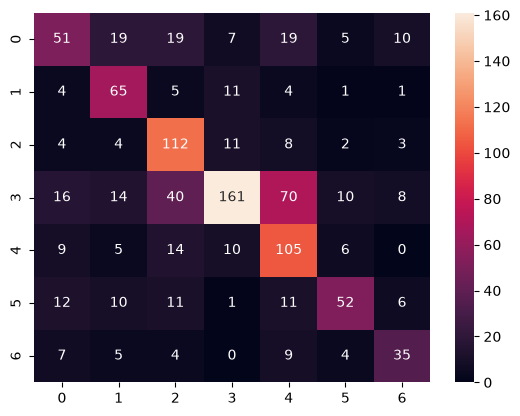

In [14]:
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d")

Advanced model: a simple two-layer GCN

In [15]:
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import GCNConv
import torch

class SimpleGCN(nn.Module):
  def __init__(self, input_dim,hidden_dim,output_dim,dropout=0.5):
    super().__init__()
    self.conv1 = GCNConv(input_dim, hidden_dim)
    self.conv2 = GCNConv(hidden_dim,output_dim)
    self.dropout = dropout

  def forward(self,x,edge_index):
    x = self.conv1(x,edge_index)
    x = F.relu(x)
    x = F.dropout(x,p=self.dropout,training=self.training)
    x = self.conv2(x,edge_index)
    return x

model = SimpleGCN(
    input_dim = data.num_features,
    hidden_dim = 32,
    output_dim = dataset.num_classes,
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print(model)

SimpleGCN(
  (conv1): GCNConv(1433, 32)
  (conv2): GCNConv(32, 7)
)


In [16]:
#Training of GCN Model
def train_one_epoch():
    model.train() #Training
    optimizer.zero_grad()
    logits = model(data.x, data.edge_index) #x-> 2708 x 7
    loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate(mask):
    model.eval()
    logits = model(data.x, data.edge_index) # Pass full edge_index to the model
    predictions = logits.argmax(dim=1)
    accuracy = (predictions[mask] == data.y[mask]).float().mean().item() # Corrected accuracy calculation
    macro_f1 = f1_score(
        data.y[mask].numpy(),
        predictions[mask].numpy(),
        average="macro"
    )
    return accuracy, macro_f1, predictions

In [17]:
losses, train_accuracies, val_accuracies = [], [], []
best_val_accuracy = 0.0
best_state = None

epoch_without_improvement = 0
patience = 20 #Stop i no improvement for this many epochs

for epoch in range(1, 201):
  loss = train_one_epoch()
  train_accuracy,_,_ = evaluate(data.train_mask)
  val_accuracy,_,_ = evaluate(data.val_mask)

  losses.append(loss)
  train_accuracies.append(train_accuracy)
  val_accuracies.append(val_accuracy) #0.70

  if val_accuracy > best_val_accuracy: #0.56 > 0.70
    best_val_accuracy = val_accuracy
    best_state = model.state_dict()
    epoch_without_improvement = 0

  else:
    epoch_without_improvement += 1

  if epoch_without_improvement >= patience:
    print(f"Early stopping at epoch {epoch}")
    break

  if epoch == 1 or epoch % 10 == 0:
    print(f"Epoch: {epoch:03d} | Loss: {loss:.4f} | Train Acc: {train_accuracy:.4f} | Val Acc: {val_accuracy:.4f} |Best Val Acc: {best_val_accuracy:.4f}")

model.load_state_dict(best_state)
gcn_accuracy, gcn_f1, gcn_pred = evaluate(data.test_mask)

print(f"\nGCN test accuracy: {gcn_accuracy:.3f}")
print(f"GCN test macro-F1: {gcn_f1:.3f}")

Epoch: 001 | Loss: 1.9699 | Train Acc: 0.7357 | Val Acc: 0.5240 |Best Val Acc: 0.5240
Epoch: 010 | Loss: 0.4826 | Train Acc: 0.9857 | Val Acc: 0.7740 |Best Val Acc: 0.7780
Epoch: 020 | Loss: 0.0766 | Train Acc: 1.0000 | Val Acc: 0.7720 |Best Val Acc: 0.7780
Early stopping at epoch 26

GCN test accuracy: 0.784
GCN test macro-F1: 0.780


6. Compare the models

<Axes: >

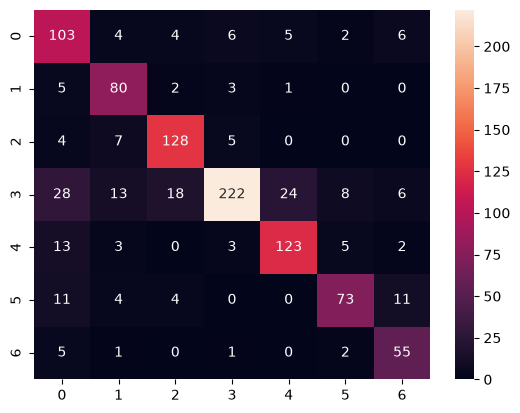

In [18]:
#Confusion MArix for GCN model.
sns.heatmap(
    confusion_matrix(data.y[data.test_mask].numpy(), gcn_pred[data.test_mask].numpy()),
    annot=True,
    fmt="d"
)

In [19]:
results = pd.DataFrame({
    "Model": ["Random Forest", "GCN"],
    "Accuracy": [rf_accuracy, gcn_accuracy],
    "Macro-F1": [rf_f1, gcn_f1]
})

In [20]:
results

,Model,Accuracy,Macro-F1
0,Random Forest,0.581,0.569807
1,GCN,0.784,0.779955


In [24]:
# ONNX -> Open Neural Network Exchange -> fast, optimized model inference
import torch

# Set the model to evaluation mode (disables dropout)
model.eval()

# Dummy inputs for ONNX export
# x: [num_nodes, num_features], edge_index: [2, num_edges]
x_dummy = data.x
edge_index_dummy = data.edge_index

onnx_file_path = "simple_gcn_cora.onnx"

torch.onnx.export(
    model,                                   # 1. Trained model
    (x_dummy, edge_index_dummy),             # 2. Model inputs
    onnx_file_path,                          # 3. Output path
    dynamo=False,                            # 4. Use legacy exporter (supports dynamic_axes)
    export_params=True,                      # 5. Store trained weights in the file
    opset_version=18,                        # 6. ONNX opset
    do_constant_folding=True,                # 7. Constant folding optimization
    input_names=['node_features', 'edge_indices'],
    output_names=['logits'],
    dynamic_axes={
        'node_features': {0: 'num_nodes'},   # variable number of nodes
        'edge_indices': {1: 'num_edges'},    # variable number of edges
    },
)

print(f"Model exported to {onnx_file_path}")

C:\Users\HP\AppData\Local\Temp\ipykernel_12320\4028076495.py:14: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Model exported to simple_gcn_cora.onnx


In [25]:
import onnxruntime as ort

sess = ort.InferenceSession(onnx_file_path)
out = sess.run(None, {
    "node_features": x_dummy.numpy(),
    "edge_indices": edge_index_dummy.numpy(),
})

with torch.no_grad():
    torch_out = model(x_dummy, edge_index_dummy).numpy()

print("ONNX shape:", out[0].shape)   # expect (2708, 7)
print("Max diff:", abs(out[0] - torch_out).max())

ONNX shape: (2708, 7)
Max diff: 2.861023e-06


In [26]:
best_state = model.state_dict()   # this is a reference, not a copy

In [27]:
import torch
import torch_geometric.transforms as T

dataset = Planetoid(root="data/Planetoid", name="Cora", transform=T.NormalizeFeatures())
data = dataset[0]

print(f"Nodes: {data.num_nodes} | Edges: {data.num_edges} | Features: {data.num_node_features} | Classes: {dataset.num_classes}")
print(f"Train: {data.train_mask.sum()} | Val: {data.val_mask.sum()} | Test: {data.test_mask.sum()}")

Nodes: 2708 | Edges: 10556 | Features: 1433 | Classes: 7
Train: 140 | Val: 500 | Test: 1000


In [28]:
X_binary = (data.x.numpy() > 0).astype(np.float32)   # recover 0/1 word indicators
y = data.y.numpy()

In [29]:
import copy
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import GCNConv

class SimpleGCN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, output_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)   # input dropout
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

torch.manual_seed(42)
model = SimpleGCN(data.num_features, 64, dataset.num_classes)

# Weight decay on the first layer only (original GCN paper setup)
optimizer = torch.optim.Adam([
    dict(params=model.conv1.parameters(), weight_decay=5e-4),
    dict(params=model.conv2.parameters(), weight_decay=0),
], lr=0.01)
print(model)

SimpleGCN(
  (conv1): GCNConv(1433, 64)
  (conv2): GCNConv(64, 7)
)


In [30]:
def train_one_epoch():
    model.train()
    optimizer.zero_grad()
    logits = model(data.x, data.edge_index)
    loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate(mask):
    model.eval()
    predictions = model(data.x, data.edge_index).argmax(dim=1)
    accuracy = (predictions[mask] == data.y[mask]).float().mean().item()
    macro_f1 = f1_score(data.y[mask].numpy(), predictions[mask].numpy(), average="macro")
    return accuracy, macro_f1, predictions

In [31]:
losses, train_accuracies, val_accuracies = [], [], []
best_val_accuracy, best_state, best_epoch = 0.0, None, 0
epoch_without_improvement, patience = 0, 30

for epoch in range(1, 301):
    loss = train_one_epoch()
    train_acc, _, _ = evaluate(data.train_mask)
    val_acc, _, _ = evaluate(data.val_mask)
    losses.append(loss); train_accuracies.append(train_acc); val_accuracies.append(val_acc)

    if val_acc > best_val_accuracy:
        best_val_accuracy, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())   # real copy
        epoch_without_improvement = 0
    else:
        epoch_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:03d} | Loss {loss:.4f} | Train {train_acc:.4f} | Val {val_acc:.4f} | Best Val {best_val_accuracy:.4f}")

    if epoch_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
print(f"Restored best epoch: {best_epoch}")
gcn_accuracy, gcn_f1, gcn_pred = evaluate(data.test_mask)
print(f"\nGCN test accuracy: {gcn_accuracy:.3f}")
print(f"GCN test macro-F1: {gcn_f1:.3f}")

Epoch 001 | Loss 1.9450 | Train 0.1714 | Val 0.1280 | Best Val 0.1280
Epoch 010 | Loss 1.7586 | Train 0.9500 | Val 0.7300 | Best Val 0.7360
Epoch 020 | Loss 1.4125 | Train 0.9786 | Val 0.7720 | Best Val 0.7800
Epoch 030 | Loss 1.0416 | Train 0.9714 | Val 0.7920 | Best Val 0.7940
Epoch 040 | Loss 0.7288 | Train 0.9786 | Val 0.8000 | Best Val 0.8020
Epoch 050 | Loss 0.5139 | Train 0.9786 | Val 0.7960 | Best Val 0.8040
Epoch 060 | Loss 0.4518 | Train 0.9857 | Val 0.7960 | Best Val 0.8080
Epoch 070 | Loss 0.3863 | Train 1.0000 | Val 0.8020 | Best Val 0.8080
Epoch 080 | Loss 0.3496 | Train 1.0000 | Val 0.7980 | Best Val 0.8080
Early stopping at epoch 83
Restored best epoch: 53

GCN test accuracy: 0.826
GCN test macro-F1: 0.813


In [32]:
from torch_geometric.nn import GATConv, APPNP

class MLP(nn.Module):
    def __init__(self, i, h, o, dropout=0.5):
        super().__init__()
        self.l1, self.l2, self.p = nn.Linear(i, h), nn.Linear(h, o), dropout
    def forward(self, x, edge_index):          # edge_index ignored
        x = F.dropout(x, self.p, self.training)
        x = F.relu(self.l1(x))
        x = F.dropout(x, self.p, self.training)
        return self.l2(x)

class GAT(nn.Module):
    def __init__(self, i, o, heads=8, hidden=8, dropout=0.6):
        super().__init__()
        self.c1 = GATConv(i, hidden, heads=heads, dropout=dropout)
        self.c2 = GATConv(hidden * heads, o, heads=1, dropout=dropout)
        self.p = dropout
    def forward(self, x, edge_index):
        x = F.dropout(x, self.p, self.training)
        x = F.elu(self.c1(x, edge_index))
        x = F.dropout(x, self.p, self.training)
        return self.c2(x, edge_index)

class APPNPNet(nn.Module):
    def __init__(self, i, h, o, K=10, alpha=0.1, dropout=0.5):
        super().__init__()
        self.l1, self.l2, self.p = nn.Linear(i, h), nn.Linear(h, o), dropout
        self.prop = APPNP(K, alpha)
    def forward(self, x, edge_index):
        x = F.dropout(x, self.p, self.training)
        x = F.relu(self.l1(x))
        x = F.dropout(x, self.p, self.training)
        return self.prop(self.l2(x), edge_index)

def run(make_model, lr, wd, seed, epochs=300, patience=30):
    torch.manual_seed(seed); np.random.seed(seed)
    m = make_model()
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=wd)
    best_val, best_state, bad = 0.0, None, 0
    for _ in range(epochs):
        m.train(); opt.zero_grad()
        out = m(data.x, data.edge_index)
        F.cross_entropy(out[data.train_mask], data.y[data.train_mask]).backward()
        opt.step()
        m.eval()
        with torch.no_grad():
            pred = m(data.x, data.edge_index).argmax(1)
        val = (pred[data.val_mask] == data.y[data.val_mask]).float().mean().item()
        if val > best_val:
            best_val, best_state, bad = val, copy.deepcopy(m.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(best_state); m.eval()
    with torch.no_grad():
        pred = m(data.x, data.edge_index).argmax(1)
    yt, pt = data.y[data.test_mask].numpy(), pred[data.test_mask].numpy()
    return accuracy_score(yt, pt), f1_score(yt, pt, average="macro")

F_, C_ = data.num_features, dataset.num_classes
configs = {
    "MLP":   (lambda: MLP(F_, 64, C_),        0.01,  5e-4),
    "GCN":   (lambda: SimpleGCN(F_, 64, C_),  0.01,  5e-4),
    "GAT":   (lambda: GAT(F_, C_),            0.005, 5e-4),
    "APPNP": (lambda: APPNPNet(F_, 64, C_),   0.01,  5e-4),
}

rows = []
for name, (make, lr, wd) in configs.items():
    res = np.array([run(make, lr, wd, seed) for seed in range(10)])
    rows.append({"Model": name,
                 "Accuracy": f"{res[:,0].mean():.3f} ± {res[:,0].std():.3f}",
                 "Macro-F1": f"{res[:,1].mean():.3f} ± {res[:,1].std():.3f}"})
    print(rows[-1])

results_multi = pd.DataFrame(rows)
results_multi

{'Model': 'MLP', 'Accuracy': '0.584 ± 0.006', 'Macro-F1': '0.567 ± 0.007'}
{'Model': 'GCN', 'Accuracy': '0.825 ± 0.008', 'Macro-F1': '0.813 ± 0.007'}
{'Model': 'GAT', 'Accuracy': '0.816 ± 0.011', 'Macro-F1': '0.808 ± 0.009'}
{'Model': 'APPNP', 'Accuracy': '0.831 ± 0.006', 'Macro-F1': '0.821 ± 0.006'}


,Model,Accuracy,Macro-F1
0,MLP,0.584 ± 0.006,0.567 ± 0.007
1,GCN,0.825 ± 0.008,0.813 ± 0.007
2,GAT,0.816 ± 0.011,0.808 ± 0.009
3,APPNP,0.831 ± 0.006,0.821 ± 0.006


In [33]:
results_multi.to_csv("results.csv", index=False)

In [34]:
losses, train_accuracies, val_accuracies = [], [], []
best_val_accuracy, best_state, best_epoch = 0.0, None, 0
epoch_without_improvement, patience = 0, 30

for epoch in range(1, 301):
    loss = train_one_epoch()
    train_acc, _, _ = evaluate(data.train_mask)
    val_acc, _, _ = evaluate(data.val_mask)
    losses.append(loss); train_accuracies.append(train_acc); val_accuracies.append(val_acc)

    if val_acc > best_val_accuracy:
        best_val_accuracy, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())   # real copy
        epoch_without_improvement = 0
    else:
        epoch_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:03d} | Loss {loss:.4f} | Train {train_acc:.4f} | Val {val_acc:.4f} | Best Val {best_val_accuracy:.4f}")

    if epoch_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
print(f"Restored best epoch: {best_epoch}")
gcn_accuracy, gcn_f1, gcn_pred = evaluate(data.test_mask)
print(f"\nGCN test accuracy: {gcn_accuracy:.3f}")
print(f"GCN test macro-F1: {gcn_f1:.3f}")

Epoch 001 | Loss 0.4650 | Train 0.9786 | Val 0.8040 | Best Val 0.8040
Epoch 010 | Loss 0.4584 | Train 0.9857 | Val 0.7980 | Best Val 0.8040
Epoch 020 | Loss 0.3756 | Train 0.9929 | Val 0.7960 | Best Val 0.8060
Epoch 030 | Loss 0.3559 | Train 1.0000 | Val 0.7940 | Best Val 0.8060
Epoch 040 | Loss 0.3150 | Train 1.0000 | Val 0.7920 | Best Val 0.8060
Early stopping at epoch 44
Restored best epoch: 14

GCN test accuracy: 0.826
GCN test macro-F1: 0.811


In [37]:
import torch

# Make sure we export the trained, best-checkpoint model
model.eval()

x_dummy = data.x
edge_index_dummy = data.edge_index

onnx_file_path = "simple_gcn_cora.onnx"

torch.onnx.export(
    model,
    (x_dummy, edge_index_dummy),
    onnx_file_path,
    dynamo=False,
    export_params=True,
    opset_version=18,
    do_constant_folding=True,
    input_names=['node_features', 'edge_indices'],
    output_names=['logits'],
    dynamic_axes={
        'node_features': {0: 'num_nodes'},
        'edge_indices': {1: 'num_edges'},
    },
)

print(f"Model exported to {onnx_file_path}")

import os
print("Saved at:", os.path.abspath(onnx_file_path))
print("Size (KB):", round(os.path.getsize(onnx_file_path) / 1024, 1))

C:\Users\HP\AppData\Local\Temp\ipykernel_12320\3842861899.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
c:\Users\HP\OneDrive\Desktop\cite_gragh\.venv\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset9.py:5330: UserWarning: Exporting aten::index operator with indices of type Byte. Only 1-D indices are supported. In any other case, this will produce an incorrect ONNX graph.
  indices = [try_mask_to_index(idx) for idx in indices]


Model exported to simple_gcn_cora.onnx
Saved at: c:\Users\HP\OneDrive\Desktop\cite_gragh\simple_gcn_cora.onnx
Size (KB): 378.7


In [39]:
import onnxruntime as ort

sess = ort.InferenceSession(onnx_file_path)
out = sess.run(None, {
    "node_features": x_dummy.numpy(),
    "edge_indices": edge_index_dummy.numpy(),
})

with torch.no_grad():
    torch_out = model(x_dummy, edge_index_dummy).numpy()

print("ONNX shape:", out[0].shape)   # expect (2708, 7)
print("Max diff:", abs(out[0] - torch_out).max())

ONNX shape: (2708, 7)
Max diff: 1.4305115e-06


In [2]:
import pandas as pd

results_multi = pd.DataFrame([
    {"Model": "MLP",   "Accuracy": "0.584 ± 0.006", "Macro-F1": "0.567 ± 0.007"},
    {"Model": "GCN",   "Accuracy": "0.825 ± 0.008", "Macro-F1": "0.813 ± 0.007"},
    {"Model": "GAT",   "Accuracy": "0.816 ± 0.011", "Macro-F1": "0.808 ± 0.009"},
    {"Model": "APPNP", "Accuracy": "0.831 ± 0.006", "Macro-F1": "0.821 ± 0.006"},
])
results_multi.to_csv("results.csv", index=False)
results_multi

,Model,Accuracy,Macro-F1
0,MLP,0.584 ± 0.006,0.567 ± 0.007
1,GCN,0.825 ± 0.008,0.813 ± 0.007
2,GAT,0.816 ± 0.011,0.808 ± 0.009
3,APPNP,0.831 ± 0.006,0.821 ± 0.006
